# Статистический анализ отчислений студентов

**Данные:** UCI [«Predict Students' Dropout and Academic Success»](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) — 4 424 студента португальского вуза, 36 признаков и итоговый статус `Target` (Dropout / Enrolled / Graduate).

**Цель:** понять, какие факторы связаны с отчислением и успеваемостью, и проверить это строгими статистическими методами.

**Содержание**
1. Разведочный анализ: типы признаков, скрытые пропуски, описательные статистики, выбросы
2. ЗБЧ, ЦПТ и неравенства концентрации (Марков, Чебышёв, Чернов, Хёфдинг)
3. Корреляции (Пирсон, Спирмен, Кендалл), отбор признаков, PCA через собственные векторы
4. Параметрические модели, метод максимального правдоподобия, доверительные интервалы
5. Проверка гипотез: одно- и двухвыборочный $t$-тест
6. Одно- и двухфакторный ANOVA, критерий Тьюки, мета-анализ по когортам (FE / RE)
7. ЭФР, полоса DKW, критерии Колмогорова–Смирнова

Основные выводы собраны в конце ноутбука.


## Описание признаков датасета

### Бинарные признаки (8)

| Признак | Описание | Значения |
|---|---|---|
| Daytime/evening attendance | Форма обучения | 1 — дневная, 0 — вечерняя |
| Displaced | Переехал ради учёбы (живёт не по месту постоянного проживания) | 1 — да, 0 — нет |
| Educational special needs | Особые образовательные потребности | 1 — да, 0 — нет |
| Debtor | Есть задолженность перед институтом | 1 — да, 0 — нет |
| Tuition fees up to date | Плата за обучение внесена вовремя | 1 — да, 0 — нет |
| Gender | Пол | 1 — мужской, 0 — женский |
| Scholarship holder | Получает стипендию | 1 — да, 0 — нет |
| International | Иностранный студент | 1 — да, 0 — нет |

### Категориальные признаки (11)

Значения — числовые коды категорий, арифметические операции с ними не имеют смысла.

| Признак | Описание | Значения |
|---|---|---|
| Marital status | Семейное положение | 6 кодов: 1 — холост/не замужем, 2 — в браке, 3 — вдовец/вдова, 4 — разведён(а), 5 — гражданский брак, 6 — раздельное проживание |
| Application mode | Способ и этап подачи заявления | 18 кодов (1 — 1-й этап общего конкурса, 17 — 2-й этап, 39 — старше 23 лет, 43 — смена направления и др.) |
| Application order | Приоритет направления в списке заявлений (порядковый признак) | 0–9, меньше — более желанное направление |
| Course | Направление обучения | 17 кодов (9500 — сестринское дело, 9147 — менеджмент, 9119 — информатика и др.) |
| Previous qualification | Уровень образования до поступления | 17 кодов (1 — среднее школьное, остальные — высшее, неоконченное высшее, курсы и др.) |
| Nationality | Гражданство | 21 код (1 — Португалия) |
| Mother's qualification | Образование матери | 29 кодов: от начальной школы до докторской степени |
| Father's qualification | Образование отца | 34 кода: от начальной школы до докторской степени |
| Mother's occupation | Профессия матери | 32 кода групп профессий |
| Father's occupation | Профессия отца | 46 кодов групп профессий |
| Target | Итоговый статус в конце нормативного срока обучения | Dropout — отчислился, Enrolled — ещё учится, Graduate — выпустился |

### Количественные признаки (18)

| Признак | Описание | Шкала / единицы |
|---|---|---|
| Previous qualification (grade) | Оценка за предыдущее образование | 0–200 баллов |
| Admission grade | Вступительный балл | 0–200 баллов |
| Age at enrollment | Возраст при поступлении | лет (17–70) |
| Curricular units 1st sem (credited) | Дисциплин 1-го семестра перезачтено из предыдущего образования | штук |
| Curricular units 1st sem (enrolled) | Дисциплин, на которые записан в 1-м семестре | штук |
| Curricular units 1st sem (evaluations) | Аттестаций (экзамены, зачёты, пересдачи) в 1-м семестре | штук |
| Curricular units 1st sem (approved) | Сдано дисциплин в 1-м семестре | штук |
| Curricular units 1st sem (grade) | Средняя оценка по сданным дисциплинам 1-го семестра | 0–20 (0 — ничего не сдано, оценки нет) |
| Curricular units 1st sem (without evaluations) | Дисциплин 1-го семестра без аттестации | штук |
| Curricular units 2nd sem (credited) | То же для 2-го семестра: перезачтено | штук |
| Curricular units 2nd sem (enrolled) | Записан на дисциплин во 2-м семестре | штук |
| Curricular units 2nd sem (evaluations) | Аттестаций во 2-м семестре | штук |
| Curricular units 2nd sem (approved) | Сдано дисциплин во 2-м семестре | штук |
| Curricular units 2nd sem (grade) | Средняя оценка по сданным дисциплинам 2-го семестра | 0–20 (0 — оценки нет) |
| Curricular units 2nd sem (without evaluations) | Дисциплин 2-го семестра без аттестации | штук |
| Unemployment rate | Безработица в Португалии в год поступления | % |
| Inflation rate | Инфляция в год поступления | % |
| GDP | Темп роста ВВП в год поступления | % (может быть отрицательным) |



*Что делаем:* Подключаем библиотеки и загружаем датасет с сайта UCI. Чистим имена столбцов: убираем табуляцию в `Daytime/evening attendance` и исправляем опечатку `Nacionality`.

In [1]:
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
try:
    df = pd.read_csv("data.csv", sep=";")
except FileNotFoundError:
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    df = pd.read_csv(z.open("data.csv"), sep=";")

df.columns = df.columns.str.strip()
df = df.rename(columns={"Nacionality": "Nationality"})
print(df.shape)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


# 1. Разведочный анализ

## Типы признаков

*Что делаем:* Делим признаки на три типа: бинарные (0/1), категориальные (числовые коды категорий) и количественные.

In [2]:
binary_cols = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
               "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
categorical_cols = ["Marital status", "Application mode", "Application order", "Course", "Previous qualification",
                    "Nationality", "Mother's qualification", "Father's qualification",
                    "Mother's occupation", "Father's occupation", "Target"]
num_cols = [c for c in df.columns if c not in binary_cols + categorical_cols]

print("Бинарные:", binary_cols)
print("\nКатегориальные (закодированы числами):", categorical_cols)
print("\nКоличественные:", num_cols)

Бинарные: ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

Категориальные (закодированы числами): ['Marital status', 'Application mode', 'Application order', 'Course', 'Previous qualification', 'Nationality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Target']

Количественные: ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evalu

Категориальные признаки хранятся как целые числа (коды), но среднее по ним не имеет смысла — для них считаем только частоты.
Количественные: оценки, возраст, число дисциплин по семестрам, макропоказатели (безработица, инфляция, ВВП).

## Пропущенные значения

*Что делаем:* Ищем пропуски. Явных `NaN` нет. Нулевая оценка за семестр у студента без сданных дисциплин означает пропуск, поэтому в копии `dfc` заменяем её на `NaN` и смотрим, у кого таких пропусков больше.

In [3]:
print("Пропусков (NaN):", df.isna().sum().sum())

# оценка за семестр = 0, если не сдано ни одной дисциплины, — это пропуск, а не оценка
dfc = df.copy()
for s in ["1st", "2nd"]:
    no_grade = df[f"Curricular units {s} sem (approved)"] == 0
    dfc.loc[no_grade, f"Curricular units {s} sem (grade)"] = np.nan
    print(f"{s} семестр: оценок 0 (скрытый пропуск) — {no_grade.sum()} ({no_grade.mean():.1%})")

print("\nДоля без оценки за 1-й семестр по статусу:")
print(dfc.groupby("Target")["Curricular units 1st sem (grade)"].apply(lambda s: s.isna().mean()).round(3))

Пропусков (NaN): 0
1st семестр: оценок 0 (скрытый пропуск) — 718 (16.2%)
2nd семестр: оценок 0 (скрытый пропуск) — 870 (19.7%)

Доля без оценки за 1-й семестр по статусу:
Target
Dropout     0.401
Enrolled    0.089
Graduate    0.035
Name: Curricular units 1st sem (grade), dtype: float64


**Вывод.** Явных пропусков нет. Но у 16,2 % студентов нет оценки за 1-й семестр, у 19,7 % — за 2-й. Среди отчисленных без оценки 40 %,
среди выпускников — 3,5 %. Пропуски не случайны: они связаны с исходом. Поэтому строки не удаляем, иначе выборка сместится в сторону успешных
студентов, а оценки считаем только по тем, у кого они есть.

## Меры центральной тенденции и разброса

*Что делаем:* Для количественных признаков считаем меры центральной тенденции (среднее, медиана, мода) и разброса (std(стандартное отклонение), дисперсия, IQR($IQR = Q_3 - Q_1$), min, max), а также асимметрию.

**credited** - Перезачтённые дисциплины

 **enrolled** - Записан на дисциплины — сколько дисциплин студент взял в семестре

 **evaluations** - Аттестации — сколько раз студент сдавал экзамены и зачёты, **включая пересдачи**

 **approved** - Сколько дисциплин успешно закрыто

 **grade** - Среднее по **сданным** дисциплинам, шкала 0–20. Если approved = 0, оценки нет и в данных стоит 0 (скрытый пропуск)

 **without evaluations** - По скольким дисциплинам студент не проходил аттестацию: не явился или не был допущен

In [4]:
q1, q3 = dfc[num_cols].quantile(0.25), dfc[num_cols].quantile(0.75)
desc = pd.DataFrame({
    "среднее": dfc[num_cols].mean(), "медиана": dfc[num_cols].median(), "мода": dfc[num_cols].mode().iloc[0],
    "std": dfc[num_cols].std(), "дисперсия": dfc[num_cols].var(), "IQR": q3 - q1,
    "min": dfc[num_cols].min(), "max": dfc[num_cols].max(), "асимметрия": dfc[num_cols].skew(),
})
desc.round(2)

,среднее,медиана,мода,std,дисперсия,IQR,min,max,асимметрия
Previous qualification (grade),132.61,133.10,133.10,13.19,173.93,15.00,95.00,190.00,0.31
Admission grade,126.98,126.10,130.00,14.48,209.73,16.90,95.00,190.00,0.53
Age at enrollment,23.27,20.00,18.00,7.59,57.57,6.00,17.00,70.00,2.05
Curricular units 1st sem (credited),0.71,0.00,0.00,2.36,5.57,0.00,0.00,20.00,4.17
Curricular units 1st sem (enrolled),6.27,6.00,6.00,2.48,6.15,2.00,0.00,26.00,1.62
Curricular units 1st sem (evaluations),8.30,8.00,8.00,4.18,17.46,4.00,0.00,45.00,0.98
Curricular units 1st sem (approved),4.71,5.00,6.00,3.09,9.57,3.00,0.00,26.00,0.77
Curricular units 1st sem (grade),12.70,12.63,12.00,1.35,1.81,1.82,9.80,18.88,0.35
Curricular units 1st sem (without evaluations),0.14,0.00,0.00,0.69,0.48,0.00,0.00,12.00,8.21
Curricular units 2nd sem (credited),0.54,0.00,0.00,1.92,3.68,0.00,0.00,19.00,4.63


*Что делаем:* Для бинарных и категориальных признаков считаем число категорий, моду и её долю.

In [5]:
for c in binary_cols + categorical_cols:
    vc = df[c].value_counts(normalize=True)
    print(f"{c}: категорий {len(vc)}, мода = {vc.index[0]} ({vc.iloc[0]:.1%})")

Daytime/evening attendance: категорий 2, мода = 1 (89.1%)
Displaced: категорий 2, мода = 1 (54.8%)
Educational special needs: категорий 2, мода = 0 (98.8%)
Debtor: категорий 2, мода = 0 (88.6%)
Tuition fees up to date: категорий 2, мода = 1 (88.1%)
Gender: категорий 2, мода = 0 (64.8%)
Scholarship holder: категорий 2, мода = 0 (75.2%)
International: категорий 2, мода = 0 (97.5%)
Marital status: категорий 6, мода = 1 (88.6%)
Application mode: категорий 18, мода = 1 (38.6%)
Application order: категорий 8, мода = 1 (68.4%)
Course: категорий 17, мода = 9500 (17.3%)
Previous qualification: категорий 17, мода = 1 (84.0%)
Nationality: категорий 21, мода = 1 (97.5%)
Mother's qualification: категорий 29, мода = 1 (24.2%)
Father's qualification: категорий 34, мода = 37 (27.3%)
Mother's occupation: категорий 32, мода = 9 (35.6%)
Father's occupation: категорий 46, мода = 9 (22.8%)
Target: категорий 3, мода = Graduate (49.9%)


**Вывод.** Вступительная и предыдущая оценки почти симметричны: среднее ≈ медиане (127,0 и 126,1; 132,6 и 133,1).
Возраст сильно скошен вправо: среднее 23,3, медиана 20, мода 18. Для него лучше описывать центр медианой, а разброс — IQR (6 лет).
Оценки за семестр около 12,7 из 20, разброс небольшой (std ≈ 1,4). Целевая переменная несбалансирована: выпускников 49,9 %.

## Визуализация

*Что делаем:* Строим гистограммы всех количественных признаков. Красная линия — среднее, зелёная — медиана.

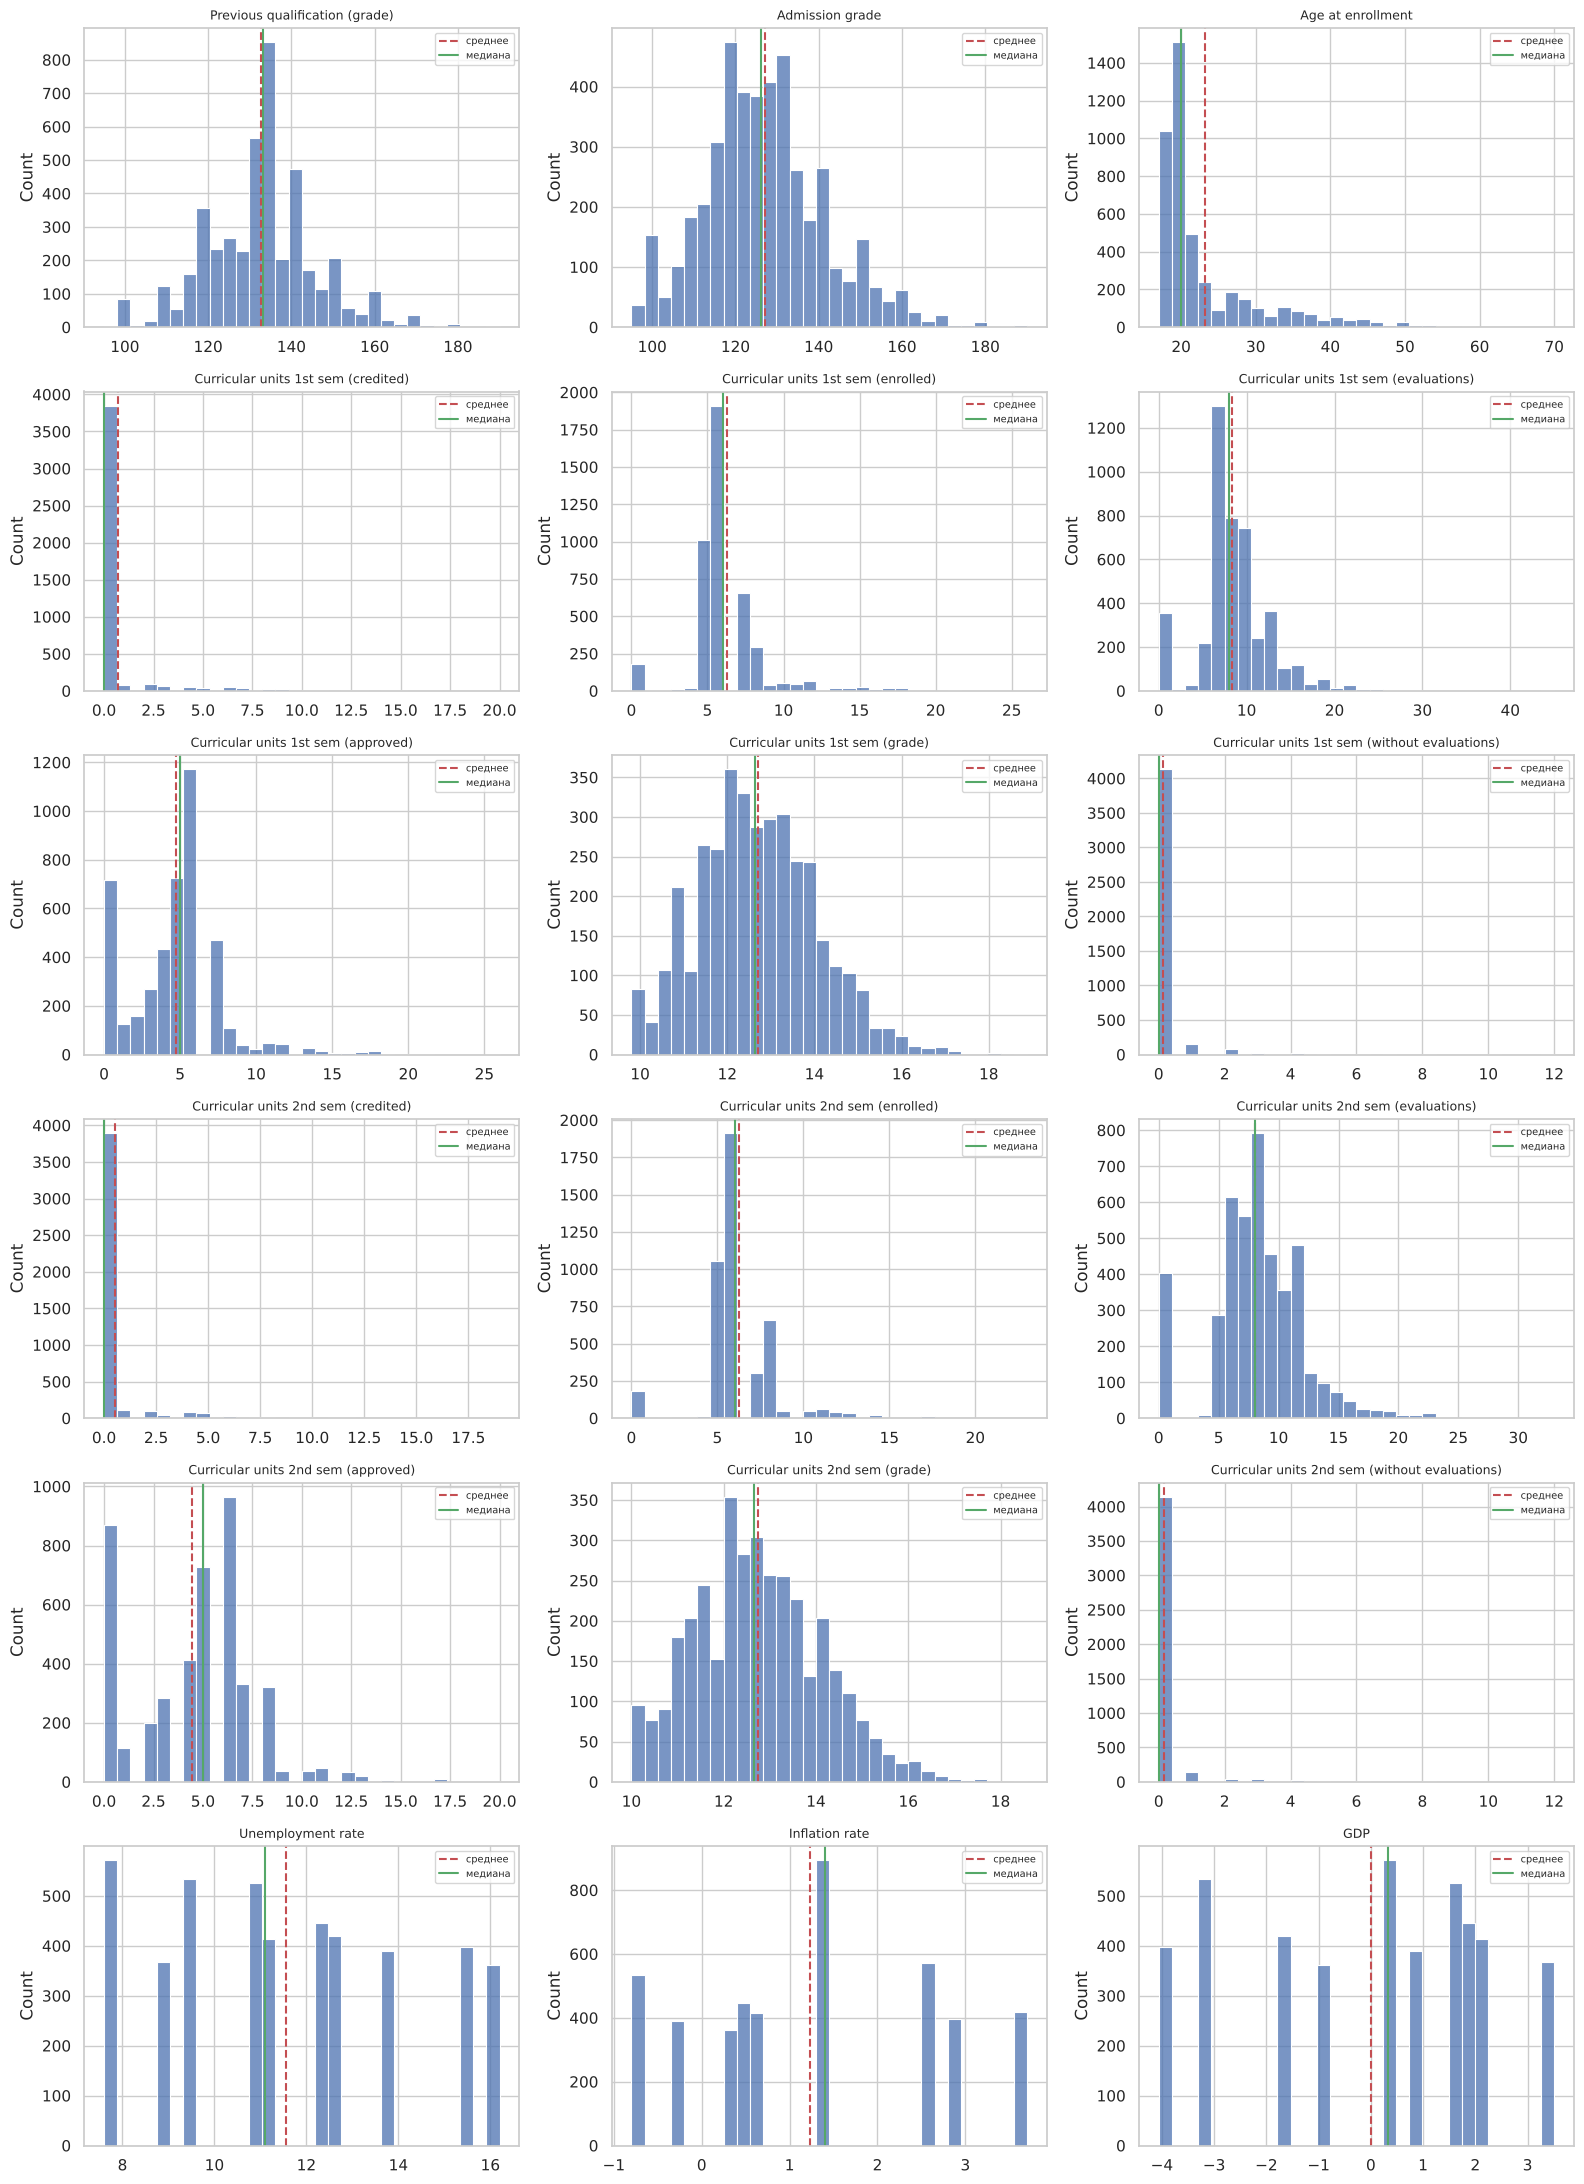

In [6]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(dfc[c].dropna(), ax=ax, bins=30)
    ax.axvline(dfc[c].mean(), color="r", ls="--", label="среднее")
    ax.axvline(dfc[c].median(), color="g", label="медиана")
    ax.set_title(c, fontsize=9); ax.set_xlabel(""); ax.legend(fontsize=7)
for ax in axes.ravel()[len(num_cols):]:
    ax.remove()
plt.tight_layout(); plt.show()

*Что делаем:* Строим столбчатые диаграммы бинарных признаков, итогового
статуса, направления обучения и семейного положения.

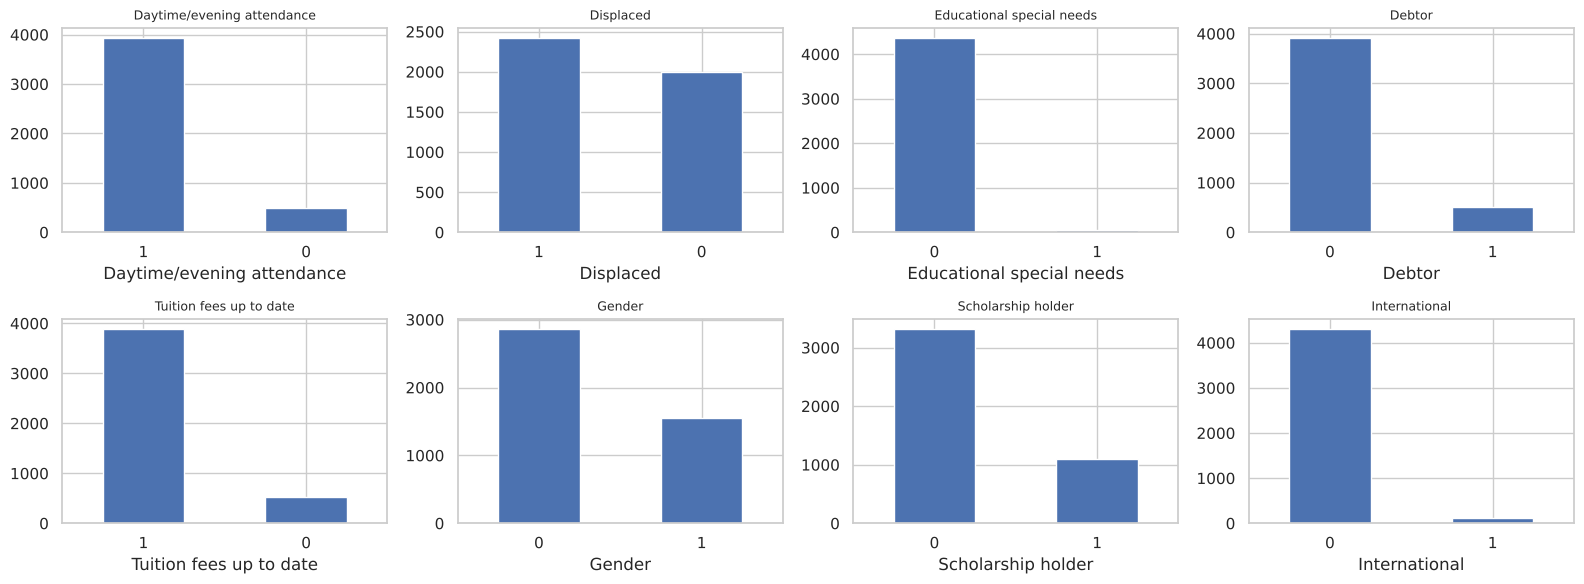

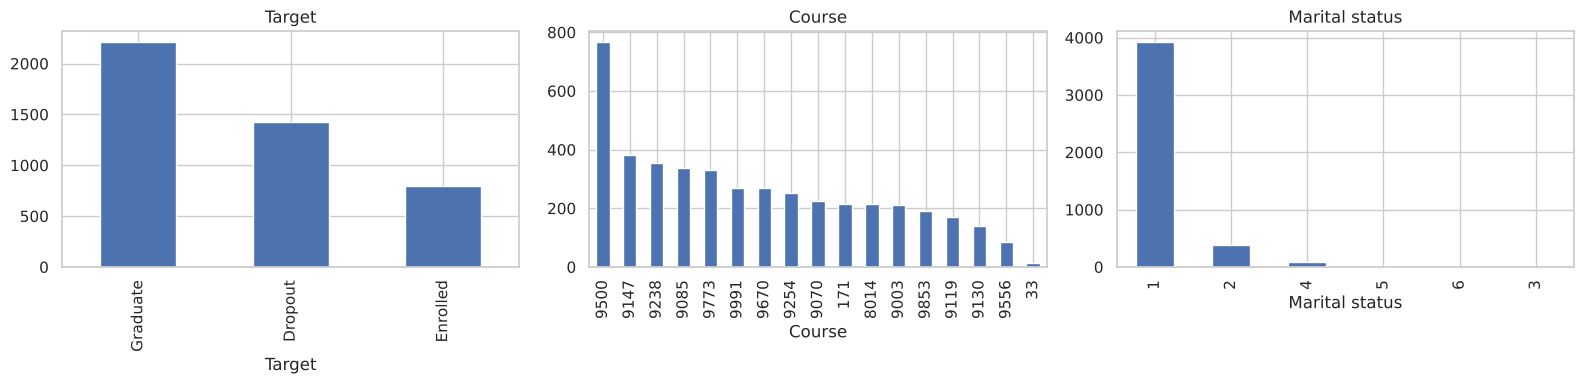

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), binary_cols):
    df[c].value_counts().plot(kind="bar", ax=ax, rot=0); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Target", "Course", "Marital status"]):
    df[c].value_counts().plot(kind="bar", ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

Почти все бинарные признаки несбалансированы:
89 % студентов учатся на дневной форме, 89 % не имеют задолженности,
99 % — без особых образовательных потребностей. Сбалансирован только признак Displaced: 55 % переехали ради учёбы, 45 % — нет.
Признак Educational special needs почти постоянен (около 50 студентов со значением 1), поэтому для сравнения групп он малоинформативен.
 88 % платят за обучение вовремя, 75 % не получают стипендию,
97,5 % — граждане Португалии. Женщин почти вдвое больше, чем мужчин (65 % и 35 %).
Целевая переменная тоже несбалансирована: выпускники — 49,9 %, отчисленные — 32,1 %, продолжающие учёбу — 17,9 %.
Направления обучения сильно различаются по размеру: от +-770 студентов (сестринское дело) до +-122 (технология биотоплива).
Подавляющее большинство студентов (88,6 %) не состоят в браке, остальные категории семейного положения малочисленны.
Признаки с очень редкими категориями (International, Educational special needs, редкие направления и семейные положения)
дают слишком маленькие группы для надёжного сравнения.

## Выбросы по правилу Тьюки

*Что делаем:* Применяем правило Тьюки: выброс — значение за пределами $[Q_1 - 1.5\,IQR;\ Q_3 + 1.5\,IQR]$. Для каждого признака считаем границы и число выбросов.

In [8]:
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = ((dfc[num_cols] < low) | (dfc[num_cols] > high)).sum()
tukey = pd.DataFrame({"нижняя граница": low, "верхняя граница": high, "выбросов": out,
                      "доля, %": 100 * out / dfc[num_cols].notna().sum(), "IQR = 0": iqr == 0})
tukey.sort_values("выбросов", ascending=False).round(2)

,нижняя граница,верхняя граница,выбросов,"доля, %",IQR = 0
Curricular units 1st sem (credited),0.00,0.00,577,13.04,True
Curricular units 2nd sem (credited),0.00,0.00,530,11.98,True
Age at enrollment,10.00,34.00,441,9.97,False
Curricular units 1st sem (enrolled),2.00,10.00,424,9.58,False
Curricular units 2nd sem (enrolled),2.00,10.00,369,8.34,False
Curricular units 1st sem (without evaluations),0.00,0.00,294,6.65,True
Curricular units 2nd sem (without evaluations),0.00,0.00,282,6.37,True
Curricular units 1st sem (approved),-1.50,10.50,180,4.07,False
Previous qualification (grade),102.50,162.50,179,4.05,False
Curricular units 1st sem (evaluations),0.00,16.00,158,3.57,False


*Что делаем:* Ящики с усами для трёх признаков (точки за усами — выбросы по Тьюки):
1. возраст при поступлении;
2. вступительный балл;
3. средняя оценка по сданным дисциплинам 1-го семестра.


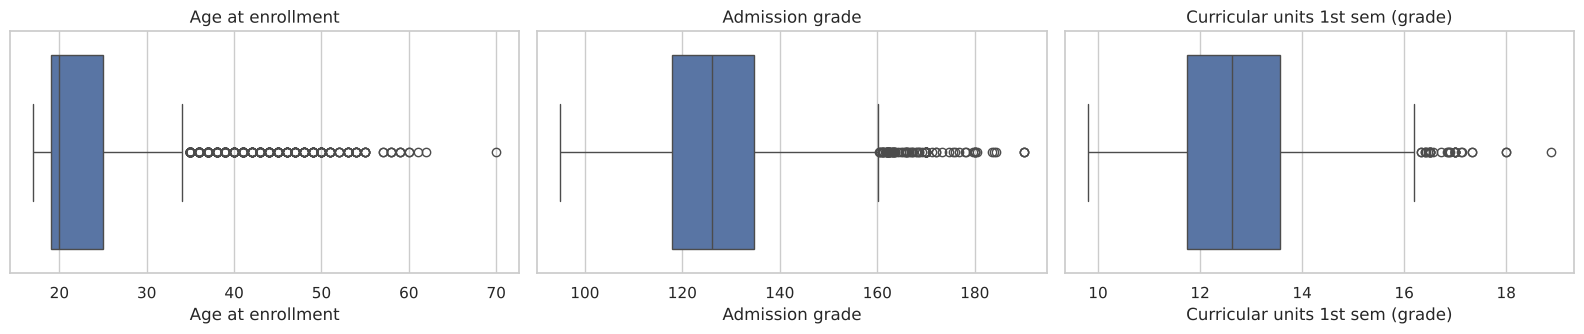

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, c in zip(axes, ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)"]):
    sns.boxplot(x=dfc[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

**Вывод.** Больше всего «выбросов» у признаков `credited` (577 и 530) и `without evaluations`. У них IQR = 0: почти у всех значение 0,
поэтому любое ненулевое значение формально считается выбросом. Здесь правило Тьюки неинформативно.
Среди содержательных признаков больше всего выбросов у возраста — 441 (≈ 10 %, старше 34 лет). Это реальные взрослые студенты, а не ошибки.
Выбросы по оценкам немногочисленны, и все значения лежат в пределах шкалы. Выбросы оставляем.

# 2. ЗБЧ, ЦПТ и неравенства концентрации

Показатели: **Admission grade** (шкала ограничена: от 0 до 200) и **Age at enrollment** (ограничен снизу, сверху границы нет).
Весь датасет — генеральная совокупность, $\mu$ — его среднее. Подвыборки извлекаем с возвращением.

*Что делаем:* Берём два показателя и считаем по всему датасету $\mu$ и $\sigma$. Для каждого $n$ извлекаем 1000 подвыборок с возвращением и считаем выборочные средние.

In [10]:
X = {"Admission grade": df["Admission grade"].to_numpy(float),
     "Age at enrollment": df["Age at enrollment"].to_numpy(float)}
n_list = [10, 30, 100, 500]
N = 1000

means = {k: {n: x[rng.integers(0, len(x), (N, n))].mean(axis=1) for n in n_list} for k, x in X.items()}
for k, x in X.items():
    print(f"{k}: mu = {x.mean():.3f}, sigma = {x.std():.3f}, min = {x.min()}, max = {x.max()}")

Admission grade: mu = 126.978, sigma = 14.480, min = 95.0, max = 190.0
Age at enrollment: mu = 23.265, sigma = 7.587, min = 17.0, max = 70.0


## Распределение выборочного среднего

*Что делаем:* Рисуем гистограммы выборочных средних с наложенной кривой $N(\mu, \sigma^2/n)$ и сравниваем std средних с $\sigma/\sqrt n$.

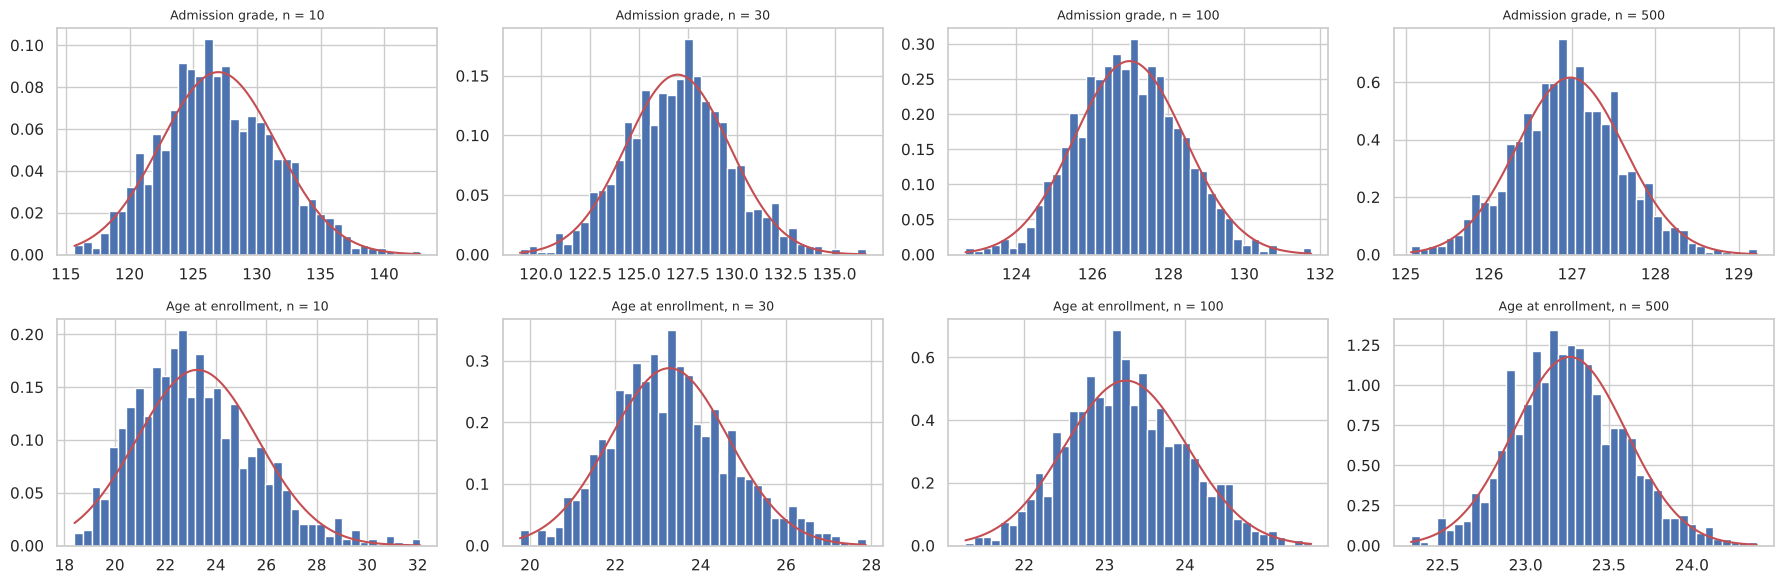

,показатель,n,среднее X̄,mu,std X̄,sigma/√n,асимметрия X̄
0,Admission grade,10,126.994,126.978,4.490,4.579,0.253
1,Admission grade,30,127.025,126.978,2.696,2.644,0.103
2,Admission grade,100,126.947,126.978,1.375,1.448,0.057
3,Admission grade,500,126.947,126.978,0.647,0.648,0.039
4,Age at enrollment,10,23.171,23.265,2.338,2.399,0.645
5,Age at enrollment,30,23.313,23.265,1.400,1.385,0.347
6,Age at enrollment,100,23.266,23.265,0.732,0.759,0.204
7,Age at enrollment,500,23.256,23.265,0.335,0.339,0.220


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for i, (k, x) in enumerate(X.items()):
    for j, n in enumerate(n_list):
        m = means[k][n]; ax = axes[i, j]
        ax.hist(m, bins=40, density=True)
        t = np.linspace(m.min(), m.max(), 200)
        ax.plot(t, stats.norm(x.mean(), x.std() / np.sqrt(n)).pdf(t), "r")
        ax.set_title(f"{k}, n = {n}", fontsize=9)
plt.tight_layout(); plt.show()

rows = [{"показатель": k, "n": n, "среднее X̄": means[k][n].mean(), "mu": x.mean(),
         "std X̄": means[k][n].std(), "sigma/√n": x.std() / np.sqrt(n), "асимметрия X̄": stats.skew(means[k][n])}
        for k, x in X.items() for n in n_list]
pd.DataFrame(rows).round(3)

**Вывод.** Среднее выборочных средних совпадает с $\mu$ (126,98 и 23,27), std средних совпадает с $\sigma/\sqrt n$.
Для вступительной оценки распределение $\bar X$ почти симметрично уже при $n = 10$ (асимметрия 0,25).
Для возраста при $n = 10$ видна правая асимметрия (0,65), с ростом $n$ она уменьшается и распределение приближается к нормальному (ЦПТ).

## Оценки отклонения $P(|\bar X_n - \mu| \ge \varepsilon)$

| Неравенство | Условие | Admission grade | Age |
|---|---|---|---|
| Маркова | $X \ge 0$ | можно, только верхний хвост, от $n$ не зависит | можно, то же |
| Чебышёва | конечная дисперсия | можно | можно |
| Чернова | известна MGF | можно (MGF считаем по всей совокупности) | то же |
| Хёфдинга | $X \in [a, b]$ | можно, $[0, 200]$ | строго нельзя: верхней границы возраста нет; можно только с размахом из данных |

*Что делаем:* Считаем эмпирическую вероятность $P(|\bar X_n - \mu| \ge \varepsilon)$ при $\varepsilon = 2\sigma/\sqrt n$ и сравниваем её с оценками четырёх неравенств.

In [12]:
def markov(eps, mu):            return min(1, mu / (mu + eps))
def chebyshev(eps, n, s2):      return min(1, s2 / (n * eps ** 2))
def hoeffding(eps, n, a, b):    return min(1, 2 * np.exp(-2 * n * eps ** 2 / (b - a) ** 2))

def chernoff(eps, n, x):
    y = x - x.mean()
    lams = np.linspace(1e-4, 5 / y.std(), 500)
    lm = np.array([np.log(np.mean(np.exp(l * y))) for l in lams]) - lams * eps     # верхний хвост
    lp = np.array([np.log(np.mean(np.exp(-l * y))) for l in lams]) - lams * eps    # нижний хвост
    return min(1, np.exp(n * min(0, lm.min())) + np.exp(n * min(0, lp.min())))

bounds_ab = {"Admission grade": (0, 200), "Age at enrollment": (X["Age at enrollment"].min(), X["Age at enrollment"].max())}
rows = []
for k, x in X.items():
    for n in n_list:
        eps = 2 * x.std() / np.sqrt(n)        # 2 стандартные ошибки
        rows.append({"показатель": k, "n": n, "eps": eps,
                     "эмпирически": np.mean(np.abs(means[k][n] - x.mean()) >= eps),
                     "Марков (верх. хвост)": markov(eps, x.mean()),
                     "Чебышёв": chebyshev(eps, n, x.var()),
                     "Чернов": chernoff(eps, n, x),
                     "Хёфдинг": hoeffding(eps, n, *bounds_ab[k])})
pd.DataFrame(rows).round(4)

,показатель,n,eps,эмпирически,Марков (верх. хвост),Чебышёв,Чернов,Хёфдинг
0,Admission grade,10,9.1582,0.035,0.9327,0.25,0.2738,1
1,Admission grade,30,5.2875,0.051,0.9600,0.25,0.2718,1
2,Admission grade,100,2.8961,0.029,0.9777,0.25,0.2711,1
3,Admission grade,500,1.2952,0.046,0.9899,0.25,0.2714,1
4,Age at enrollment,10,4.7984,0.036,0.8290,0.25,0.2329,1
5,Age at enrollment,30,2.7704,0.055,0.8936,0.25,0.2534,1
6,Age at enrollment,100,1.5174,0.036,0.9388,0.25,0.2656,1
7,Age at enrollment,500,0.6786,0.051,0.9717,0.25,0.2698,1


**Вывод.** Все границы выше эмпирической вероятности (0,03–0,055), то есть выполняются.
- $\varepsilon$ взято равным 2 стандартным ошибкам, поэтому эмпирическая вероятность и границы почти не зависят от $n$.
- **Марков** (0,83–0,99) бесполезен и не уменьшается с ростом $n$: он не использует то, что $\bar X$ — среднее.
- **Чебышёв** ровно 0,25 $= 1/2^2$, в 5–7 раз выше эмпирической вероятности.
- **Чернов** (0,23–0,27) при $\varepsilon = 2$ SE примерно равен Чебышёву. Он выигрывает при больших $\varepsilon$, так как убывает экспоненциально, а Чебышёв — как $1/\varepsilon^2$.
- **Хёфдинг** равен 1: отрезок значений (200 баллов, 53 года) слишком широк по сравнению с $\sigma$. Для возраста он к тому же строго неприменим, так как априорной верхней границы нет.

# 3. Корреляции, отбор признаков и PCA

*Что делаем:* Строим матрицы корреляций Пирсона, Спирмена и Кендалла и находим пары с наибольшей разницей Спирмена и Пирсона.

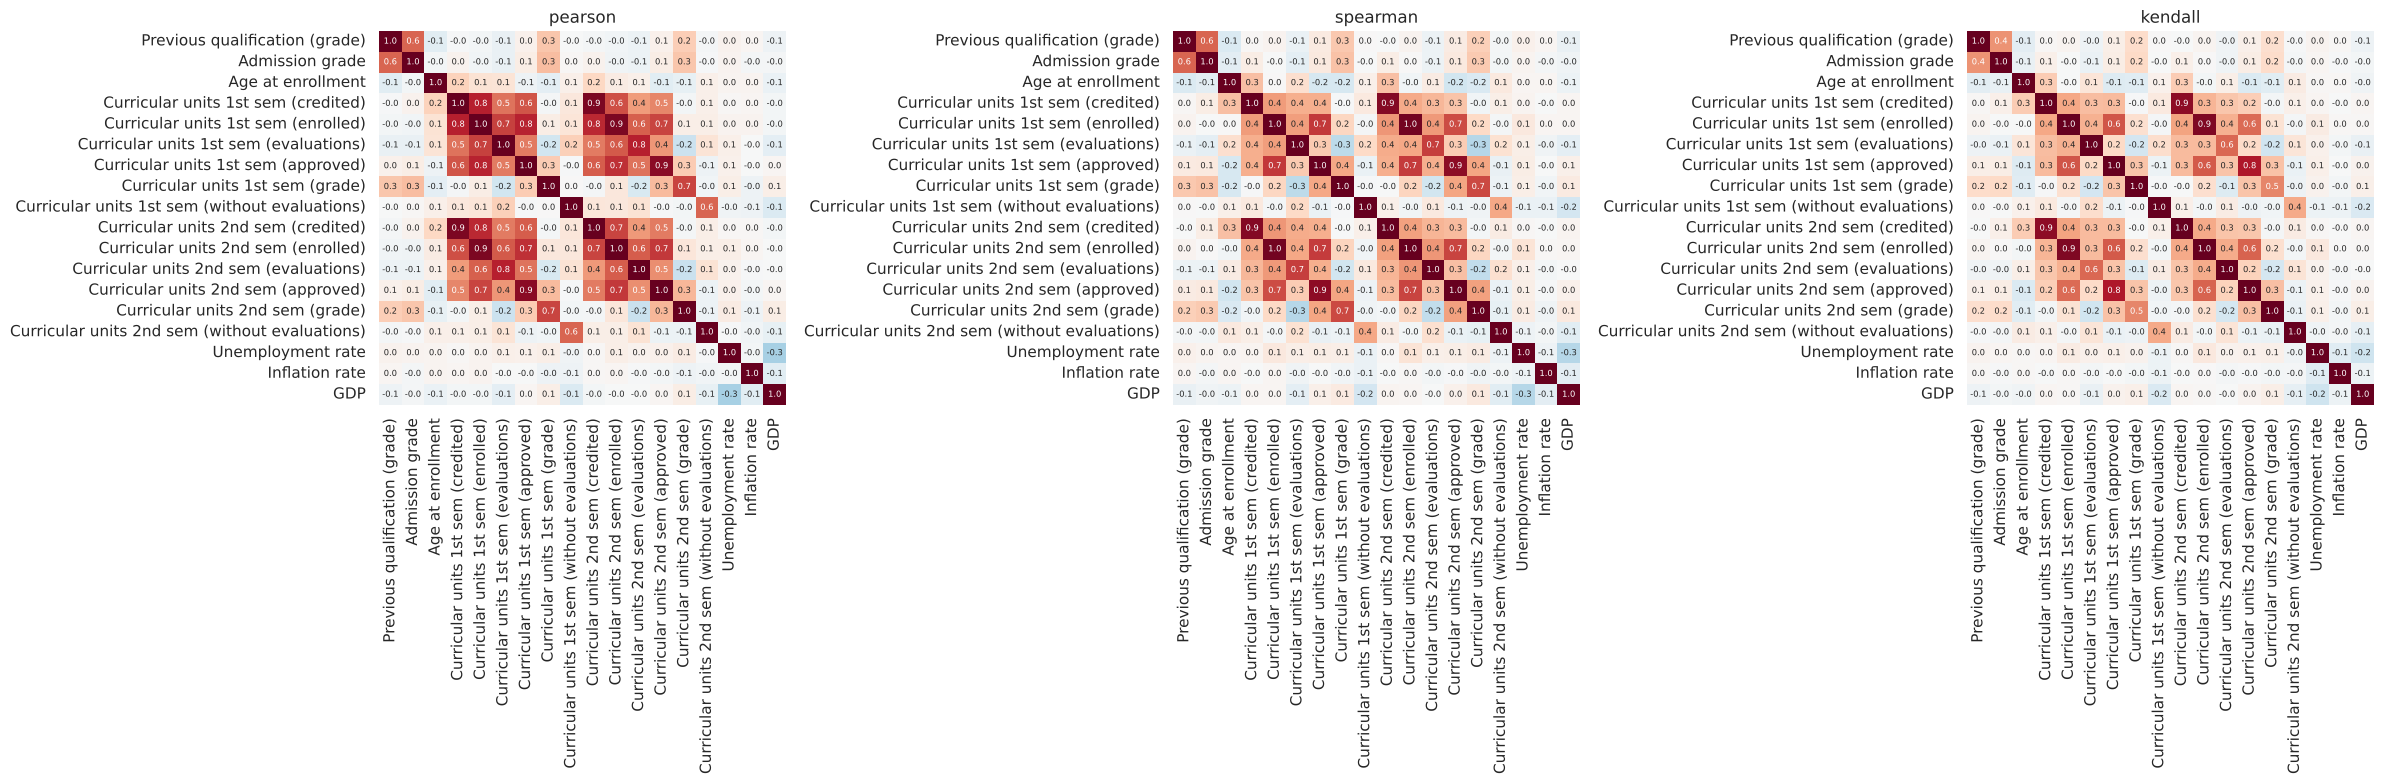

Пары с наибольшей разницей Спирмена и Пирсона:
Curricular units 1st sem (credited)  Curricular units 1st sem (enrolled)    0.351
Curricular units 1st sem (enrolled)  Curricular units 2nd sem (credited)    0.314
Curricular units 1st sem (credited)  Curricular units 2nd sem (enrolled)    0.269
                                     Curricular units 1st sem (approved)    0.267
Curricular units 2nd sem (credited)  Curricular units 2nd sem (enrolled)    0.263
dtype: float64


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
C = {}
for ax, m in zip(axes, ["pearson", "spearman", "kendall"]):
    C[m] = dfc[num_cols].corr(method=m)
    sns.heatmap(C[m], ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
                annot_kws={"size": 6}, cbar=False)
    ax.set_title(m)
plt.tight_layout(); plt.show()

diff = (C["spearman"] - C["pearson"]).abs().where(np.triu(np.ones(C["pearson"].shape), 1).astype(bool)).stack()
print("Пары с наибольшей разницей Спирмена и Пирсона:")
print(diff.sort_values(ascending=False).head(5).round(3))

**Сравнение.** Сильные связи и знаки совпадают во всех трёх матрицах: показатели 1-го и 2-го семестров сильно связаны между собой.
Кендалл по модулю меньше Спирмена — это особенность шкалы. Наибольшая разница Спирмена и Пирсона (0,26–0,35) — в парах с `credited`:
у этого признака почти все значения нули, связь нелинейная, а ранги с множеством совпадений ведут себя иначе, чем сами значения.

## Отбор признаков: метод фильтра

*Что делаем:* Из матрицы Пирсона видно, что показатели семестров сильно дублируют друг друга (мультиколлинеарность).
Убираем лишние признаки по правилу: находим пары с |r| > 0,8, начиная с самой сильной, и из каждой пары удаляем
тот признак, у которого средняя |r| с остальными больше — он сильнее всех дублирует другие. Затем строим матрицу
корреляций для оставшихся признаков.

Пары с |r| > 0.8:
Curricular units 1st sem (credited)  Curricular units 2nd sem (credited)    0.94
Curricular units 1st sem (enrolled)  Curricular units 2nd sem (enrolled)    0.94
Curricular units 1st sem (approved)  Curricular units 2nd sem (approved)    0.90
dtype: float64

Удаляем (3): ['Curricular units 1st sem (approved)', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)']
Оставляем (15): ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


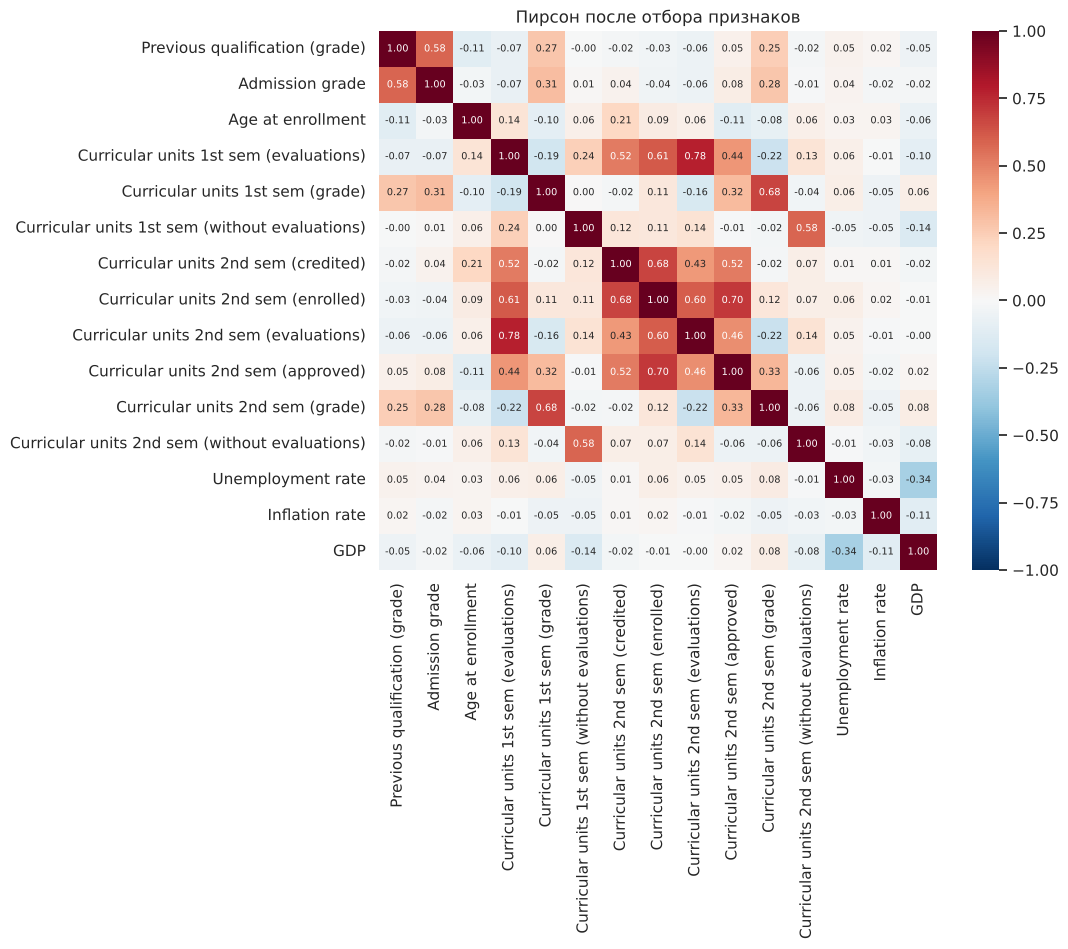

In [14]:
corr = dfc[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
thr = 0.8
print(f"Пары с |r| > {thr}:")
print(pairs[pairs > thr].round(2))

to_drop = set()
for (a, b), r in pairs[pairs > thr].items():
    if a in to_drop or b in to_drop:          # из этой пары уже что-то удалено
        continue
    to_drop.add(a if corr[a].mean() >= corr[b].mean() else b)

cols3 = [c for c in num_cols if c not in to_drop]
print(f"\nУдаляем ({len(to_drop)}):", sorted(to_drop))
print(f"Оставляем ({len(cols3)}):", cols3)

plt.figure(figsize=(9, 7))
sns.heatmap(dfc[cols3].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Пирсон после отбора признаков"); plt.show()

**Вывод.** Нашлось три пары с |r| > 0,8: одни и те же показатели 1-го и 2-го семестров (`credited` 0,94, `enrolled` 0,94, `approved` 0,90).
Фильтр удалил из каждой пары версию 1-го семестра, осталось 15 признаков из 18. В новой матрице пар с |r| > 0,8 нет, и её можно прочитать целиком.
Минус метода: он смотрит только на попарные линейные связи и не учитывает смысл признаков — из пары удаляется «более связанный», а не «менее полезный».


## Пример: корреляция не отражает характер зависимости

*Что делаем:* Диаграмма рассеяния «число сданных дисциплин — оценка за 1-й семестр» с нулевыми оценками и без них. В заголовках — коэффициент Пирсона.

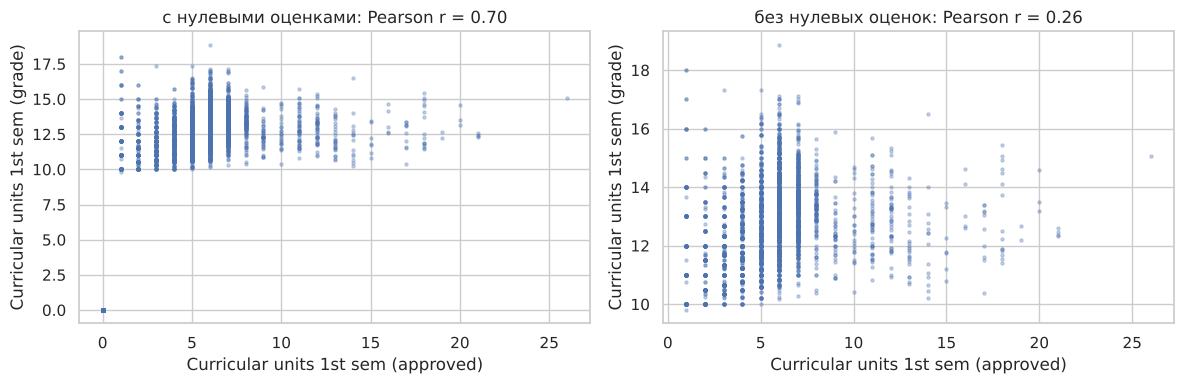

In [15]:
xa, ya = "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, d) in zip(axes, [("с нулевыми оценками", df), ("без нулевых оценок", dfc)]):
    d = d[[xa, ya]].dropna()
    r = d[xa].corr(d[ya])
    ax.scatter(d[xa], d[ya], s=5, alpha=0.3); ax.set_title(f"{name}: Pearson r = {r:.2f}")
    ax.set_xlabel(xa); ax.set_ylabel(ya)
plt.tight_layout(); plt.show()

**Вывод.** С нулевыми оценками коэффициент Пирсона заметно выше (значения — в заголовках графиков). Его завышает группа точек (0, 0):
студенты без сданных дисциплин. Реальная зависимость — «ступенька»: 0 сданных → нет оценки, хотя бы одна сданная → оценка 10–16 почти независимо
от числа дисциплин. Коэффициент корреляции этой структуры не показывает.

## PCA

*Что делаем:* PCA: стандартизуем признаки, находим собственные числа и векторы ковариационной матрицы, считаем долю объяснённой дисперсии и число компонент для 90 % и 95 %. Тепловая карта показывает нагрузки компонент.

Компонент для 90 %: 10, для 95 %: 12 (из 18)


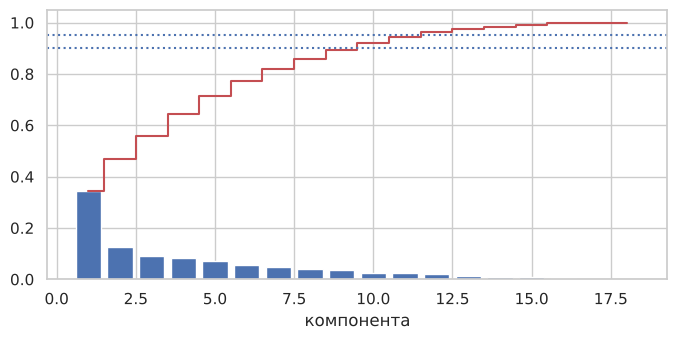

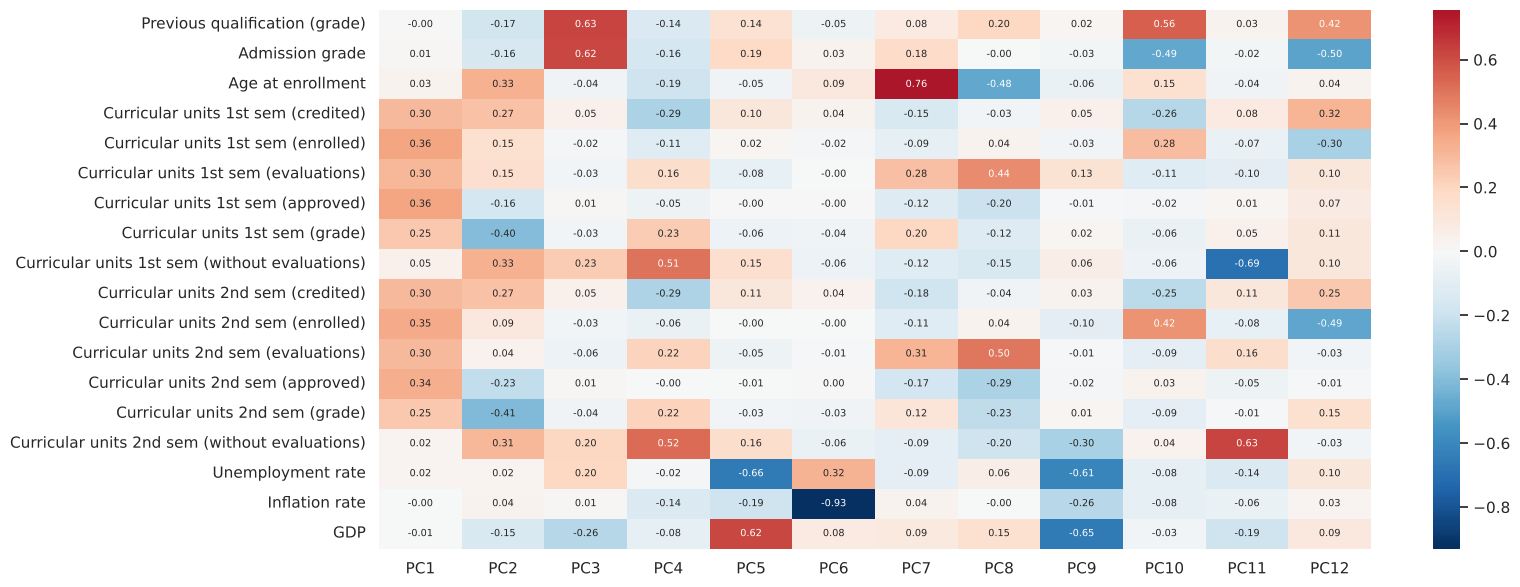

In [16]:
Z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
eigval, eigvec = np.linalg.eigh(np.cov(Z.T))
idx = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[idx], eigvec[:, idx]
explained = eigval / eigval.sum()
cum = np.cumsum(explained)
k90, k95 = np.argmax(cum >= 0.90) + 1, np.argmax(cum >= 0.95) + 1
print(f"Компонент для 90 %: {k90}, для 95 %: {k95} (из {len(num_cols)})")

plt.figure(figsize=(8, 3.5))
plt.bar(range(1, len(cum) + 1), explained); plt.step(range(1, len(cum) + 1), cum, "r", where="mid")
plt.axhline(0.9, ls=":"); plt.axhline(0.95, ls=":"); plt.xlabel("компонента"); plt.show()

loadings = pd.DataFrame(eigvec[:, :k95], index=num_cols, columns=[f"PC{i+1}" for i in range(k95)])
plt.figure(figsize=(k95 + 4, 7)); sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}); plt.show()

**Вывод.** Из 18 признаков для 90 % дисперсии нужно 10 компонент, для 95 % — 12. Сжатие умеренное: часть признаков
(показатели 1-го и 2-го семестров) дублирует друг друга, но многие признаки почти независимы (возраст, макропоказатели, оценки до поступления).
PC1 по нагрузкам — успеваемость (сданные дисциплины, аттестации, оценки обоих семестров), и она хорошо интерпретируется.
Дальние компоненты смешивают несвязанные по смыслу признаки и интерпретируются плохо.

## Сравнение: PCA после отбора признаков

*Что делаем:* Повторяем PCA только на признаках, оставшихся после фильтра, и сравниваем число компонент для 90 % и 95 %.

In [17]:
Z3 = (df[cols3] - df[cols3].mean()) / df[cols3].std()
ev3 = np.sort(np.linalg.eigvalsh(np.cov(Z3.T)))[::-1]
cum3 = np.cumsum(ev3) / ev3.sum()
print(f"Все признаки:   90 % — {k90}, 95 % — {k95} компонент (из {len(num_cols)})")
print(f"После фильтра:  90 % — {np.argmax(cum3 >= 0.90) + 1}, 95 % — {np.argmax(cum3 >= 0.95) + 1} компонент (из {len(cols3)})")

Все признаки:   90 % — 10, 95 % — 12 компонент (из 18)
После фильтра:  90 % — 10, 95 % — 11 компонент (из 15)


**Вывод.** Фильтр и PCA — два способа бороться с мультиколлинеарностью: фильтр выбрасывает дублирующие признаки,
PCA сворачивает их в общие компоненты. На полном наборе для 90 % дисперсии нужно 10 компонент из 18 (56 %), после фильтра — 10 из 15 (67 %);
для 95 % — 12 из 18 и 11 из 15. Оставшиеся признаки почти независимы, поэтому PCA сжимает их слабее. Значит, основную
«экономию» PCA на полном наборе давало именно дублирование семестровых показателей.


# 4. Параметрические модели, ММП, доверительные интервалы

| Показатель | Модель | Почему | ММП |
|---|---|---|---|
| Admission grade | $\mathcal N(\mu, \sigma^2)$ | непрерывная, почти симметричная | $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum(x_i - \bar x)^2$ |
| Age at enrollment | $\text{Age} - 16 \sim \text{LogNormal}(m, s^2)$ | положительная, сильная правая асимметрия | $\hat m$, $\hat s^2$ — среднее и дисперсия $\ln(\text{Age} - 16)$ |
| Dropout (1 — отчислен) | $\text{Bernoulli}(p)$ | бинарный показатель | $\hat p = \bar x$ |

*Что делаем:* Оцениваем параметры трёх моделей методом максимального правдоподобия и сравниваем модельные характеристики с эмпирическими.

In [18]:
grade = df["Admission grade"].to_numpy(float)
log_age = np.log(df["Age at enrollment"].to_numpy(float) - 16)
dropout = (df["Target"] == "Dropout").to_numpy(float)

mu_hat, s2_hat = grade.mean(), grade.var()
m_hat, ss_hat = log_age.mean(), log_age.var()
p_hat = dropout.mean()
age = df["Age at enrollment"]

pd.DataFrame({
    "модель": [mu_hat, np.sqrt(s2_hat), 16 + np.exp(m_hat + ss_hat / 2), 16 + np.exp(m_hat), p_hat],
    "данные": [grade.mean(), grade.std(ddof=1), age.mean(), age.median(), dropout.mean()],
}, index=["grade: среднее", "grade: std", "age: среднее", "age: медиана", "dropout: доля"]).round(3)

,модель,данные
grade: среднее,126.978,126.978
grade: std,14.480,14.482
age: среднее,22.919,23.265
age: медиана,20.924,20.000
dropout: доля,0.321,0.321


*Что делаем:* Накладываем плотности подобранных моделей на гистограммы данных.

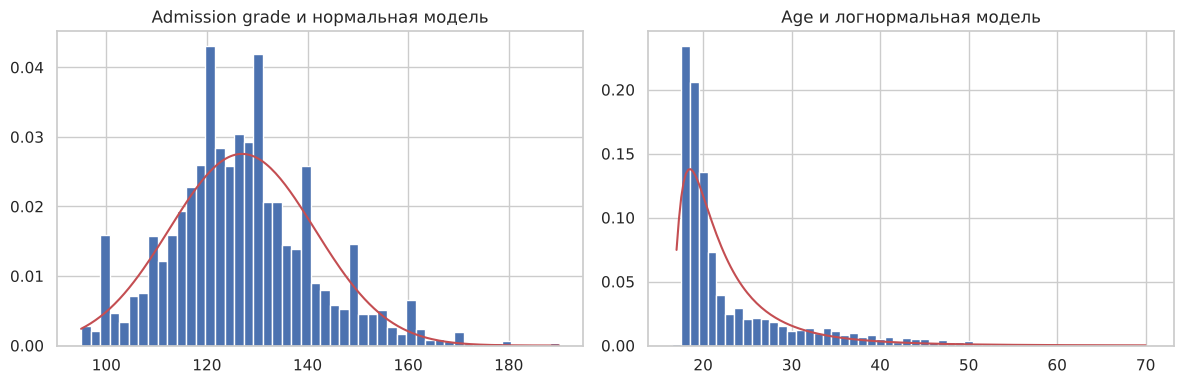

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t = np.linspace(grade.min(), grade.max(), 200)
axes[0].hist(grade, bins=50, density=True); axes[0].plot(t, stats.norm(mu_hat, np.sqrt(s2_hat)).pdf(t), "r")
axes[0].set_title("Admission grade и нормальная модель")
t = np.linspace(17, age.max(), 200)
axes[1].hist(age, bins=np.arange(16.5, age.max() + 1.5), density=True)
axes[1].plot(t, stats.lognorm(np.sqrt(ss_hat), scale=np.exp(m_hat)).pdf(t - 16), "r")
axes[1].set_title("Age и логнормальная модель")
plt.tight_layout(); plt.show()

**Вывод.** Нормальная модель для вступительной оценки совпадает с данными по среднему и std.
Логнормальная модель для возраста передаёт правую асимметрию, но приблизительно: модельное среднее 22,9 против 23,3, медиана 20,9 против 20.
Причины — возраст дискретен (целые годы) и хвост у него тяжелее. Для доли отчисленных модель совпадает с данными (0,321).

## Состоятельность

*Что делаем:* Проверяем состоятельность: для каждого $n$ берём 500 подвыборок, считаем оценку и рисуем её среднее ± std. Красная линия — истинное значение по всему датасету.

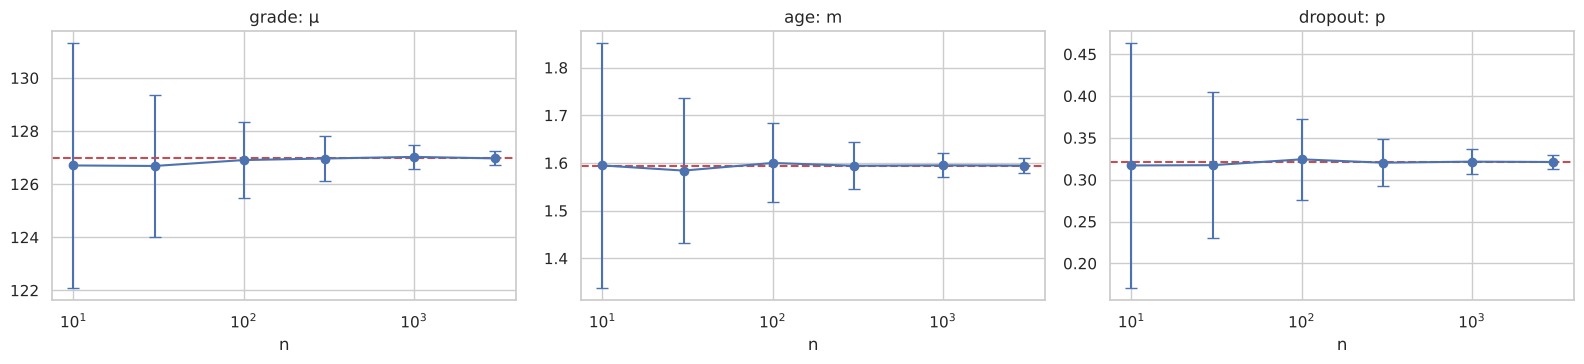

In [20]:
params = {"grade: μ": grade, "age: m": log_age, "dropout: p": dropout}     # во всех случаях оценка — среднее
true = {k: v.mean() for k, v in params.items()}
sizes = [10, 30, 100, 300, 1000, 3000]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (k, v) in zip(axes, params.items()):
    est = [v[rng.integers(0, len(v), (500, n))].mean(axis=1) for n in sizes]
    ax.errorbar(sizes, [e.mean() for e in est], yerr=[e.std() for e in est], fmt="o-", capsize=4)
    ax.axhline(true[k], color="r", ls="--"); ax.set_xscale("log"); ax.set_title(k); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

**Вывод.** С ростом $n$ среднее оценок остаётся на истинном значении, а разброс уменьшается как $1/\sqrt n$, то есть оценки состоятельны.

## Доверительные интервалы

Для $\mu$ и $m$ — $t$-интервал $\bar x \pm t_{1-\alpha/2,\,n-1} S/\sqrt n$, для $p$ — интервал Вальда $\hat p \pm z_{1-\alpha/2}\sqrt{\hat p(1-\hat p)/n}$.

*Что делаем:* Строим доверительные интервалы уровней 0,90 / 0,95 / 0,99 для разных $n$ и сравниваем их ширину.

In [21]:
def ci(sample, level, kind):
    n = len(sample); a = 1 - level; m = sample.mean()
    if kind == "t":
        h = stats.t.ppf(1 - a / 2, n - 1) * sample.std(ddof=1) / np.sqrt(n)
    else:
        h = stats.norm.ppf(1 - a / 2) * np.sqrt(m * (1 - m) / n)
    return m - h, m + h

kind = {"grade: μ": "t", "age: m": "t", "dropout: p": "wald"}
rows = []
for k, v in params.items():
    for n in [30, 100, 300, 1000]:
        s = v[rng.integers(0, len(v), n)]
        for lvl in [0.90, 0.95, 0.99]:
            lo, hi = ci(s, lvl, kind[k])
            rows.append({"параметр": k, "n": n, "уровень": lvl, "ширина": hi - lo})
pd.DataFrame(rows).pivot_table(index=["параметр", "n"], columns="уровень", values="ширина").round(4)

уровень            0.90    0.95     0.99
параметр   n                            
age: m     30    0.4872  0.5864   0.7903
           100   0.2435  0.2910   0.3852
           300   0.1538  0.1834   0.2416
           1000  0.0846  0.1008   0.1326
dropout: p 30    0.2894  0.3449   0.4533
           100   0.1547  0.1843   0.2422
           300   0.0886  0.1056   0.1387
           1000  0.0486  0.0579   0.0761
grade: μ   30    7.8941  9.5021  12.8062
           100   4.8244  5.7653   7.6312
           300   2.5863  3.0847   4.0635
           1000  1.4885  1.7741   2.3332

**Вывод.** Ширина растёт с уровнем доверия: для вступительной оценки при $n = 1000$ это 1,49 → 1,77 → 2,33.
С ростом $n$ ширина убывает примерно как $1/\sqrt n$: от $n = 100$ до $n = 1000$ интервал сужается примерно в 3 раза.

## Как часто 95 %-й интервал содержит истинное значение

*Что делаем:* Для каждого $n$ строим 1000 интервалов уровня 95 % и считаем долю тех, что содержат истинное значение параметра.

In [22]:
rows = []
for k, v in params.items():
    for n in [30, 100, 1000]:
        hits = [(lambda lo, hi: lo <= true[k] <= hi)(*ci(v[rng.integers(0, len(v), n)], 0.95, kind[k])) for _ in range(1000)]
        rows.append({"параметр": k, "n": n, "покрытие": np.mean(hits)})
pd.DataFrame(rows).pivot_table(index="параметр", columns="n", values="покрытие")

n,30,100,1000
параметр,,,
age: m,0.941,0.955,0.954
dropout: p,0.947,0.946,0.944
grade: μ,0.959,0.959,0.938


**Вывод.** Для всех трёх параметров покрытие 0,94–0,96, то есть близко к заявленным 0,95. Отклонения в пределах погрешности моделирования (±0,014 при 1000 повторах).

# 5. Проверка гипотез

*Что делаем:* Вспомогательная функция: печатает, отвергается ли $H_0$ при $\alpha$ = 0,001; 0,01; 0,05; 0,1.

In [23]:
def levels(p):
    for a in [0.001, 0.01, 0.05, 0.1]:
        print(f"  alpha = {a}: {'H0 отвергается' if p < a else 'H0 не отвергается'}")

## Один показатель

Меняется ли оценка от 1-го ко 2-му семестру? Показатель $D$ = оценка за 2-й семестр − оценка за 1-й (студенты с обеими оценками).

$H_0\colon \mu_D = 0$, $\quad H_1\colon \mu_D \ne 0$. Дисперсия неизвестна → $t$-тест.

*Что делаем:* Одновыборочный $t$-тест для разности оценок $D$ = оценка за 2-й семестр − оценка за 1-й семестр.

In [24]:
both = dfc[["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]].dropna()
D = both.iloc[:, 1] - both.iloc[:, 0]
res = stats.ttest_1samp(D, 0)
print(f"n = {len(D)}, среднее D = {D.mean():.3f}, t = {res.statistic:.3f}, p = {res.pvalue:.3g}")
levels(res.pvalue)

n = 3512, среднее D = -0.004, t = -0.215, p = 0.83
  alpha = 0.001: H0 не отвергается
  alpha = 0.01: H0 не отвергается
  alpha = 0.05: H0 не отвергается
  alpha = 0.1: H0 не отвергается


**Вывод.** Средняя разность $\bar D = -0{,}004$ балла, $p = 0{,}83$. $H_0$ не отвергается ни при одном стандартном уровне значимости
(0,001; 0,01; 0,05; 0,1) — её можно было бы отвергнуть только при $\alpha > 0{,}83$. Оснований считать, что средняя оценка меняется от 1-го ко 2-му семестру, нет.

## Два показателя

Отличается ли вступительная оценка у отчисленных и выпускников?

$H_0\colon \mu_{\text{Dropout}} = \mu_{\text{Graduate}}$, $\quad H_1\colon \mu_{\text{Dropout}} \ne \mu_{\text{Graduate}}$. Двухвыборочный $t$-тест (Уэлча, дисперсии не предполагаем равными).

*Что делаем:* Двухвыборочный $t$-тест Уэлча: вступительная оценка отчисленных и выпускников.

In [25]:
x = df.loc[df.Target == "Dropout", "Admission grade"]
y = df.loc[df.Target == "Graduate", "Admission grade"]
res = stats.ttest_ind(x, y, equal_var=False)
print(f"Dropout: {x.mean():.2f} (n = {len(x)}), Graduate: {y.mean():.2f} (n = {len(y)})")
print(f"t = {res.statistic:.3f}, p = {res.pvalue:.3g}")
levels(res.pvalue)

Dropout: 124.96 (n = 1421), Graduate: 128.79 (n = 2209)
t = -7.657, p = 2.59e-14
  alpha = 0.001: H0 отвергается
  alpha = 0.01: H0 отвергается
  alpha = 0.05: H0 отвергается
  alpha = 0.1: H0 отвергается


**Вывод.** Средняя вступительная оценка у отчисленных 124,96, у выпускников 128,79 (разница 3,8 балла). $t = -7{,}66$, $p = 2{,}6\cdot10^{-14}$.
$H_0$ отвергается при всех рассмотренных уровнях значимости: у выпускников вступительная оценка выше.
Разница статистически значима, но небольшая: около 0,26 стандартного отклонения.

# 6. ANOVA и мета-анализ

## Однофакторный ANOVA

Отличается ли средняя вступительная оценка у Dropout / Enrolled / Graduate?

$H_0\colon \mu_1 = \mu_2 = \mu_3$, $\quad H_1$: хотя бы два средних различаются.

*Что делаем:* Проверяем предпосылки ANOVA (нормальность — Шапиро, равенство дисперсий — Левен) и проводим однофакторный дисперсионный анализ.

In [26]:
groups = [df.loc[df.Target == t, "Admission grade"] for t in ["Dropout", "Enrolled", "Graduate"]]

# предпосылки: нормальность в группах и равенство дисперсий
for t, g in zip(["Dropout", "Enrolled", "Graduate"], groups):
    print(f"{t}: Шапиро p = {stats.shapiro(g.sample(min(500, len(g)), random_state=0)).pvalue:.3g}")
print(f"Левен p = {stats.levene(*groups).pvalue:.3g}")

res = stats.f_oneway(*groups)
print(f"\nF = {res.statistic:.3f}, p = {res.pvalue:.3g}")
levels(res.pvalue)

Dropout: Шапиро p = 3.19e-07
Enrolled: Шапиро p = 1.03e-06
Graduate: Шапиро p = 1.68e-06
Левен p = 0.00111

F = 35.649, p = 4.38e-16
  alpha = 0.001: H0 отвергается
  alpha = 0.01: H0 отвергается
  alpha = 0.05: H0 отвергается
  alpha = 0.1: H0 отвергается


**Вывод.** Предпосылки выполнены не полностью: Шапиро отвергает нормальность во всех группах, Левен ($p = 0{,}001$) — равенство дисперсий.
При таких больших группах ANOVA устойчив к отклонениям от нормальности. А $p = 4\cdot10^{-16}$ настолько мал, что вывод не изменится.
$F = 35{,}6$: $H_0$ отвергается при всех рассмотренных уровнях значимости. Средняя вступительная оценка различается хотя бы у двух групп.

*Что делаем:* Попарные сравнения групп критерием Тьюки с поправкой на множественность. Номера групп: 0 — Dropout, 1 — Enrolled, 2 — Graduate.

In [27]:
# попарные сравнения с поправкой на множественность (Тьюки)
print(stats.tukey_hsd(*groups))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.573     0.640    -2.066     0.920
 (0 - 2)     -3.833     0.000    -4.979    -2.687
 (1 - 0)      0.573     0.640    -0.920     2.066
 (1 - 2)     -3.260     0.000    -4.654    -1.866
 (2 - 0)      3.833     0.000     2.687     4.979
 (2 - 1)      3.260     0.000     1.866     4.654



**Вывод по попарным сравнениям.** Dropout и Enrolled не различаются ($p = 0{,}64$). Выпускники выше обеих групп: на 3,8 балла выше отчисленных
и на 3,3 балла выше продолжающих учёбу ($p < 0{,}001$).

## Двухфакторный ANOVA

Отклик — оценка за 1-й семестр. Факторы: пол и стипендия.

- $H_0^{A}$: пол не влияет на оценку;
- $H_0^{B}$: стипендия не влияет на оценку;
- $H_0^{AB}$: нет взаимодействия пола и стипендии.

*Что делаем:* Двухфакторный ANOVA: для каждого фактора и взаимодействия считаем SS, F и p через МНК. План несбалансированный, поэтому используем тип II. График взаимодействия показывает средние в ячейках.

                      SS        F       p
пол              25.1407  14.0554  0.0002
стипендия        57.8637  32.3500  0.0000
пол × стипендия   0.9722   0.5435  0.4610
пол
  alpha = 0.001: H0 отвергается
  alpha = 0.01: H0 отвергается
  alpha = 0.05: H0 отвергается
  alpha = 0.1: H0 отвергается
стипендия
  alpha = 0.001: H0 отвергается
  alpha = 0.01: H0 отвергается
  alpha = 0.05: H0 отвергается
  alpha = 0.1: H0 отвергается
пол × стипендия
  alpha = 0.001: H0 не отвергается
  alpha = 0.01: H0 не отвергается
  alpha = 0.05: H0 не отвергается
  alpha = 0.1: H0 не отвергается


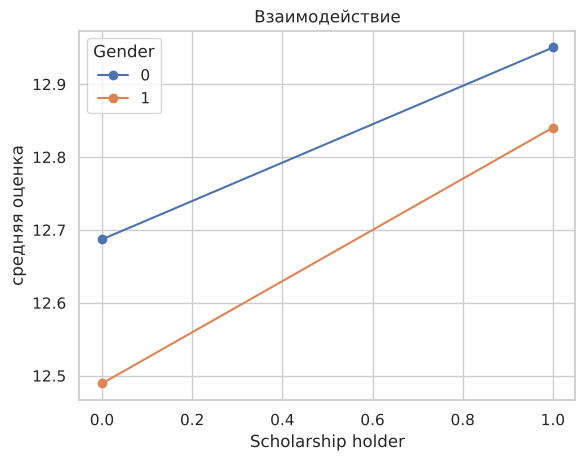

In [28]:
d = dfc[["Curricular units 1st sem (grade)", "Gender", "Scholarship holder"]].dropna()
y = d.iloc[:, 0].to_numpy()
a = d["Gender"].to_numpy(float)
b = d["Scholarship holder"].to_numpy(float)
one = np.ones_like(y)

def rss(*cols):
    X_ = np.column_stack(cols)
    beta = np.linalg.lstsq(X_, y, rcond=None)[0]
    return ((y - X_ @ beta) ** 2).sum()

rss_a, rss_b, rss_ab, rss_full = rss(one, a), rss(one, b), rss(one, a, b), rss(one, a, b, a * b)
df_err = len(y) - 4
ss = {"пол": rss_b - rss_ab, "стипендия": rss_a - rss_ab, "пол × стипендия": rss_ab - rss_full}
table = pd.DataFrame({"SS": ss, "F": {k: v / (rss_full / df_err) for k, v in ss.items()}})
table["p"] = stats.f(1, df_err).sf(table["F"])
print(table.round(4))
for k in table.index:
    print(k); levels(table.loc[k, "p"])

d.groupby(["Scholarship holder", "Gender"])["Curricular units 1st sem (grade)"].mean().unstack().plot(marker="o")
plt.ylabel("средняя оценка"); plt.title("Взаимодействие"); plt.show()

**Вывод.** Пол ($F = 14{,}1$, $p = 0{,}0002$) и стипендия ($F = 32{,}4$, $p < 0{,}0001$) влияют на оценку за 1-й семестр:
обе гипотезы $H_0^A$ и $H_0^B$ отвергаются при всех уровнях значимости. Взаимодействие незначимо ($p = 0{,}46$): $H_0^{AB}$ не отвергается
ни при каком уровне, то есть влияние стипендии одинаково у мужчин и женщин (линии на графике почти параллельны).
Женщины в среднем учатся чуть лучше мужчин (12,7 против 12,5 без стипендии; 12,95 против 12,84 со стипендией), стипендиаты — лучше остальных примерно на 0,3 балла.
Эффекты значимы, но малы на шкале 0–20: при $n \approx 3700$ тест замечает даже такие различия.

## Мета-анализ

Подвыборки — когорты по году поступления (каждая когорта имеет свои значения безработицы, инфляции и ВВП).

*Что делаем:* Делим студентов на когорты по году поступления: уникальным комбинациям безработицы, инфляции и ВВП. Функция `meta` считает модели с фиксированным (FE) и случайными (RE) эффектами, Q, $T^2$, $I^2$ и рисует forest plot.

In [29]:
df["cohort"] = df.groupby(["Unemployment rate", "Inflation rate", "GDP"]).ngroup()
dfc["cohort"] = df["cohort"]
print("Число когорт k =", df["cohort"].nunique())

def meta(y, v, labels, title, back=lambda t: t):
    w = 1 / v
    M_fe, V_fe = (w * y).sum() / w.sum(), 1 / w.sum()
    Q = (w * (y - M_fe) ** 2).sum(); k = len(y)
    T2 = max(0, (Q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    I2 = max(0, (Q - (k - 1)) / Q)
    w2 = 1 / (v + T2)
    M_re, V_re = (w2 * y).sum() / w2.sum(), 1 / w2.sum()
    for name, M, V in [("FE", M_fe, V_fe), ("RE", M_re, V_re)]:
        print(f"{name}: {back(M):.3f} [{back(M - 1.96 * np.sqrt(V)):.3f}; {back(M + 1.96 * np.sqrt(V)):.3f}]")
    print(f"Q = {Q:.2f}, p = {stats.chi2(k - 1).sf(Q):.3g}, T^2 = {T2:.4f}, I^2 = {I2:.0%}")

    plt.figure(figsize=(7, 0.4 * k + 2))
    for i in range(k):
        plt.plot([back(y[i] - 1.96 * np.sqrt(v[i])), back(y[i] + 1.96 * np.sqrt(v[i]))], [k - i] * 2, "b")
        plt.plot(back(y[i]), k - i, "bs")
    for j, (name, M, V) in enumerate([("FE", M_fe, V_fe), ("RE", M_re, V_re)]):
        plt.errorbar(back(M), -j, xerr=[[back(M) - back(M - 1.96 * np.sqrt(V))], [back(M + 1.96 * np.sqrt(V)) - back(M)]],
                     fmt="D", color="r", capsize=4)
    plt.yticks(list(range(k, 0, -1)) + [0, -1], list(labels) + ["FE", "RE"])
    plt.axvline(back(0), color="gray", ls="--"); plt.title(title); plt.show()

Число когорт k = 10


### (а) Разница средних: число сданных дисциплин 1-го семестра у стипендиатов и остальных

*Что делаем:* В каждой когорте считаем $g$ Хеджеса (стипендиаты − остальные) для числа сданных дисциплин 1-го семестра и его дисперсию, затем объединяем.

         n1   n0      g     SE      V
cohort                               
0        64  507  0.249  0.133  0.018
1       113  255  0.288  0.113  0.013
2       123  410  0.542  0.104  0.011
3       134  391  0.520  0.101  0.010
4       124  290  0.248  0.107  0.012
5       132  313  0.282  0.104  0.011
6       119  300  0.430  0.109  0.012
7       111  279  0.254  0.112  0.013
8       101  296  0.146  0.115  0.013
9        78  284  0.462  0.129  0.017
FE: 0.349 [0.280; 0.418]
RE: 0.346 [0.261; 0.432]
Q = 13.59, p = 0.138, T^2 = 0.0064, I^2 = 34%


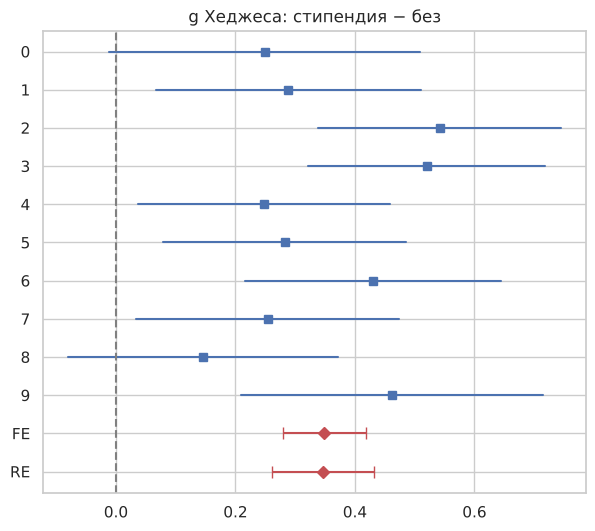

In [30]:
rows = []
for c, g in df.groupby("cohort"):
    x1 = g.loc[g["Scholarship holder"] == 1, "Curricular units 1st sem (approved)"]
    x0 = g.loc[g["Scholarship holder"] == 0, "Curricular units 1st sem (approved)"]
    n1, n0 = len(x1), len(x0)
    sp = np.sqrt(((n1 - 1) * x1.var() + (n0 - 1) * x0.var()) / (n1 + n0 - 2))
    J = 1 - 3 / (4 * (n1 + n0 - 2) - 1)
    d_ = (x1.mean() - x0.mean()) / sp
    g_ = J * d_
    v_ = J ** 2 * ((n1 + n0) / (n1 * n0) + d_ ** 2 / (2 * (n1 + n0)))
    rows.append({"cohort": c, "n1": n1, "n0": n0, "g": g_, "SE": np.sqrt(v_), "V": v_})
ta = pd.DataFrame(rows).set_index("cohort")
print(ta.round(3))
meta(ta.g.to_numpy(), ta.V.to_numpy(), ta.index, "g Хеджеса: стипендия − без")

**Вывод (а).** Во всех 10 когортах $g > 0$: стипендиаты сдают больше дисциплин. FE: 0,349 [0,280; 0,418], RE: 0,346 [0,261; 0,432].
Гетерогенность умеренная и незначимая: $Q = 13{,}6$, $p = 0{,}14$, $I^2 = 34\,\%$. Обе модели дают почти одинаковый результат, у RE интервал немного шире.

### (б) Корреляция вступительной оценки и оценки за 1-й семестр (преобразование Фишера)

*Что делаем:* В каждой когорте считаем корреляцию вступительной оценки и оценки за 1-й семестр, переводим её в $z$ Фишера, объединяем и переводим итог обратно в $r$.

          n      r      z      V
cohort                          
0       464  0.258  0.264  0.002
1       321  0.375  0.395  0.003
2       440  0.269  0.275  0.002
3       434  0.335  0.348  0.002
4       356  0.280  0.287  0.003
5       391  0.228  0.233  0.003
6       346  0.365  0.383  0.003
7       332  0.403  0.427  0.003
8       324  0.260  0.266  0.003
9       298  0.433  0.464  0.003
FE: 0.316 [0.287; 0.345]
RE: 0.319 [0.276; 0.362]
Q = 19.74, p = 0.0196, T^2 = 0.0033, I^2 = 54%


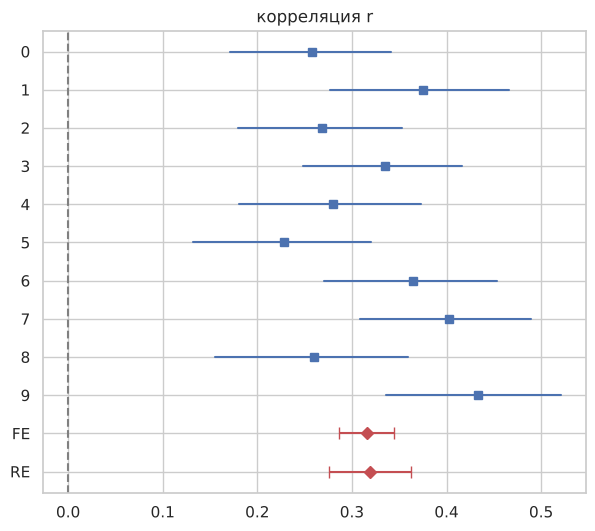

In [31]:
rows = []
for c, g in dfc.groupby("cohort"):
    g = g[["Admission grade", "Curricular units 1st sem (grade)"]].dropna()
    r = g.iloc[:, 0].corr(g.iloc[:, 1])
    rows.append({"cohort": c, "n": len(g), "r": r, "z": np.arctanh(r), "V": 1 / (len(g) - 3)})
tb = pd.DataFrame(rows).set_index("cohort")
print(tb.round(3))
meta(tb.z.to_numpy(), tb.V.to_numpy(), tb.index, "корреляция r", back=np.tanh)

**Вывод (б).** Корреляция в когортах от 0,23 до 0,43. FE: $r = 0{,}316$ [0,287; 0,345], RE: $r = 0{,}319$ [0,276; 0,362].
Гетерогенность значимая: $Q = 19{,}7$, $p = 0{,}02$, $I^2 = 54\,\%$.

**Какая модель уместнее.** Когорты — разные годы поступления с разными условиями, поэтому одинакового истинного эффекта ожидать нельзя.
Уместна модель со случайными эффектами (RE). В (б) это подтверждается значимой гетерогенностью. В (а) гетерогенность меньше, и FE и RE совпадают,
но содержательно RE всё равно корректнее.

# 7. ЭФР, DKW, критерии Колмогорова–Смирнова

## ЭФР и доверительная полоса

$\hat F_n(x) = \frac1n \#\{X_i \le x\}$, полоса DKW: $\hat F_n(x) \pm \sqrt{\ln(2/\alpha)/(2n)}$. Показатель — Admission grade.

*Что делаем:* Строим собственную ЭФР и полосы DKW для уровней доверия 0,9 и 0,99.

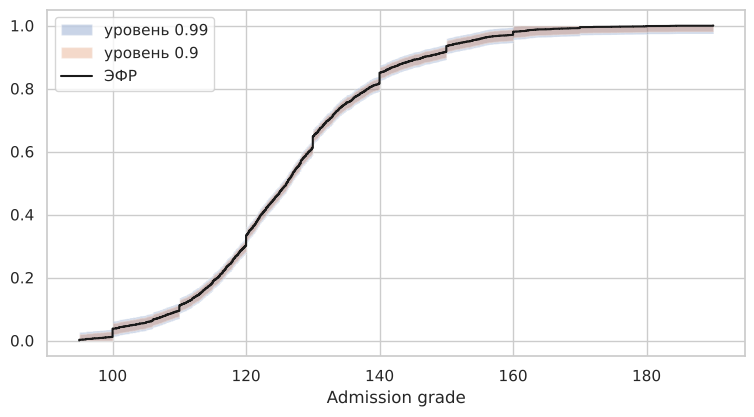

In [32]:
def ecdf(x):
    x = np.sort(x)
    return x, np.arange(1, len(x) + 1) / len(x)

xs, F = ecdf(grade)
n = len(grade)
plt.figure(figsize=(9, 4.5))
for alpha in [0.01, 0.1]:
    e = np.sqrt(np.log(2 / alpha) / (2 * n))
    plt.fill_between(xs, np.clip(F - e, 0, 1), np.clip(F + e, 0, 1), step="post", alpha=0.3, label=f"уровень {1 - alpha}")
plt.step(xs, F, where="post", color="k", label="ЭФР")
plt.xlabel("Admission grade"); plt.legend(); plt.show()

## Одновыборочный критерий Колмогорова–Смирнова

Распределение вступительной оценки унимодальное и почти симметричное, поэтому проверяем нормальность.

$H_0$: Admission grade $\sim \mathcal N(\mu, \sigma^2)$, $\quad H_1$: распределение не нормальное.

*Что делаем:* Одновыборочный критерий Колмогорова–Смирнова: считаем $D$ — максимальное расхождение ЭФР и нормальной ФР с оценёнными параметрами — и p-значение.

In [33]:
F0 = stats.norm(grade.mean(), grade.std()).cdf(xs)
D = max(np.max(F - F0), np.max(F0 - (F - 1 / n)))
p = stats.kstwo(n).sf(D)
print(f"D = {D:.4f}, p = {p:.3g}")
levels(p)

D = 0.0659, p = 4e-17
  alpha = 0.001: H0 отвергается
  alpha = 0.01: H0 отвергается
  alpha = 0.05: H0 отвергается
  alpha = 0.1: H0 отвергается


**Вывод.** $D = 0{,}066$, $p = 4\cdot10^{-17}$: $H_0$ отвергается при всех рассмотренных уровнях значимости, распределение вступительной оценки не нормальное.
Параметры оценены по тем же данным, поэтому настоящее p-значение ещё меньше. При $n = 4424$ критерий замечает даже небольшие отклонения,
но $D = 0{,}066$ означает, что нормальная ФР нигде не отличается от ЭФР больше чем на 6,6 п.п. Как приближение модель годится.

## Двухвыборочный критерий Смирнова

Совпадает ли распределение вступительной оценки у мужчин и женщин?

$H_0\colon F_{\text{male}} = F_{\text{female}}$, $\quad H_1\colon F_{\text{male}} \ne F_{\text{female}}$.

*Что делаем:* Двухвыборочный критерий Смирнова: строим ЭФР вступительной оценки у мужчин и у женщин, находим точку максимального расхождения и сравниваем результат с $t$-тестом.

D = 0.0335 (в точке 136.9), p = 0.202
  alpha = 0.001: H0 не отвергается
  alpha = 0.01: H0 не отвергается
  alpha = 0.05: H0 не отвергается
  alpha = 0.1: H0 не отвергается


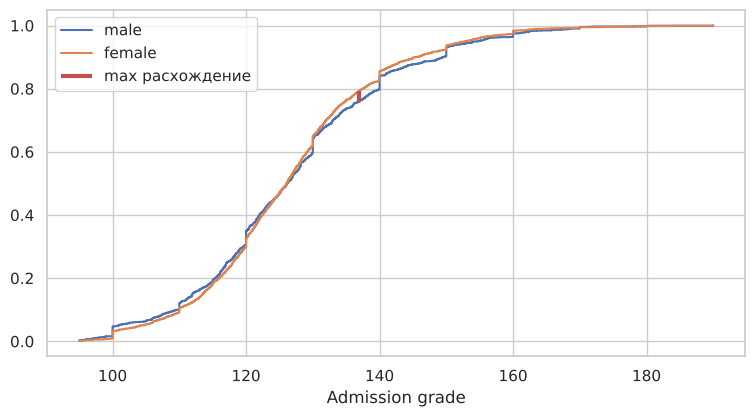


t-тест: t = 0.541, p = 0.588
  alpha = 0.001: H0 не отвергается
  alpha = 0.01: H0 не отвергается
  alpha = 0.05: H0 не отвергается
  alpha = 0.1: H0 не отвергается


In [34]:
xm = df.loc[df.Gender == 1, "Admission grade"].to_numpy()
xf = df.loc[df.Gender == 0, "Admission grade"].to_numpy()
grid = np.sort(np.unique(np.r_[xm, xf]))
Fm = np.searchsorted(np.sort(xm), grid, side="right") / len(xm)
Ff = np.searchsorted(np.sort(xf), grid, side="right") / len(xf)
j = np.argmax(np.abs(Fm - Ff))

res = stats.ks_2samp(xm, xf)
print(f"D = {res.statistic:.4f} (в точке {grid[j]}), p = {res.pvalue:.3g}")
levels(res.pvalue)

plt.figure(figsize=(9, 4.5))
plt.step(grid, Fm, where="post", label="male"); plt.step(grid, Ff, where="post", label="female")
plt.vlines(grid[j], Fm[j], Ff[j], color="r", lw=3, label="max расхождение")
plt.legend(); plt.xlabel("Admission grade"); plt.show()

t = stats.ttest_ind(xm, xf, equal_var=False)
print(f"\nt-тест: t = {t.statistic:.3f}, p = {t.pvalue:.3g}")
levels(t.pvalue)

**Вывод.** Критерий Смирнова: $D = 0{,}034$, $p = 0{,}20$. $t$-тест: $p = 0{,}59$. Обе гипотезы не отвергаются ни при одном уровне значимости
до 0,1: распределения и средние вступительной оценки у мужчин и женщин не различаются.

**Сравнение с $t$-тестом.** Здесь выводы совпадают. В общем случае они могут расходиться: $t$-тест проверяет только равенство средних,
а критерий Смирнова — совпадение распределений целиком (сдвиг, разброс, форма). Поэтому при равных средних, но разной форме распределений
Смирнов может отвергнуть $H_0$, а $t$-тест — нет.

# Итоги

1. **Пропуски не случайны.** Нулевая оценка за семестр — это скрытый пропуск: у 40 % отчисленных нет ни одной сданной дисциплины в 1-м семестре, у выпускников — 3,5 %. Строки сохранены, иначе выборка сместилась бы в сторону успешных студентов.
2. **Вступительный балл связан с исходом значимо, но слабо.** У выпускников он выше на 3,8 балла ($p = 2{,}6\cdot10^{-14}$), это около 0,26 σ. По Тьюки отчисленные и продолжающие учёбу не различаются ($p = 0{,}64$).
3. **Стипендиаты стабильно успешнее.** Мета-анализ по 10 когортам: во всех когортах стипендиаты сдают больше дисциплин в 1-м семестре, $g$ Хеджеса ≈ 0,35 [0,26; 0,43] (RE), гетерогенность незначима ($I^2 = 34\,\%$).
4. **Вступительный балл умеренно предсказывает оценку в 1-м семестре:** объединённая корреляция $r \approx 0{,}32$, но она заметно меняется от когорты к когорте ($I^2 = 54\,\%$), поэтому уместна модель со случайными эффектами.
5. **Пол и стипендия влияют на оценку за 1-й семестр независимо** (двухфакторный ANOVA, взаимодействие незначимо), но размер эффектов мал — десятые доли балла из 20.
6. **Признаки сильно дублируют друг друга:** показатели 1-го и 2-го семестров коррелируют на 0,90–0,94; для 90 % дисперсии достаточно 10 главных компонент из 18.
7. **Методические выводы:** правило Тьюки неинформативно для признаков с IQR = 0; коэффициент Пирсона может завышаться группой нулей; при больших $n$ критерии отвергают нормальность даже при небольших отклонениях, поэтому важен размер эффекта, а не только $p$.
